# 02 · Features and models

Can network topology alone tell us which proteins interact? This notebook follows the pipeline in
`src/model.py` step by step:

1. hide 10% of interactions as a test set (and another 10% for training) with the leakage-free protocol;
2. compute topological features for each candidate pair on a graph **without** that pair's edge;
3. compare how individual features separate interactions from non-interactions;
4. train and evaluate the classifiers, and stress-test them with harder negatives.

The data is the bundled synthetic network (see notebook 01); numbers illustrate the method rather than
biology.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from src.evaluate import (
    INK, PALETTE, compute_permutation_importance, display_name, evaluate_scores,
    heuristic_scores, plot_feature_importance, plot_pr_curves, plot_roc_curves, plot_style,
)
from src.graph_builder import load_graph, make_link_prediction_split
from src.model import PipelineConfig, build_feature_matrices, train_models

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 3)

SEED = 42
G = load_graph(ROOT / "data" / "raw" / "sample_ppi_edges.tsv")
config = PipelineConfig(seed=SEED)

## 1. Leakage-free split

`make_link_prediction_split` hides two disjoint sets of interactions. Test pairs are featurised on
`test_graph` (= network − test edges) and training pairs on `train_graph` (= network − test − training
edges). A pair's own edge is therefore never visible when its features are computed, which is the most
common source of inflated link-prediction results. A random spanning tree is protected so no protein becomes
isolated. Negatives are protein pairs with no recorded interaction.

In [2]:
split = make_link_prediction_split(G, test_fraction=0.1, train_fraction=0.1, seed=SEED)
pd.Series(split.summary(), name="count").to_frame()

,count
train_graph_edges,6014
test_graph_edges,6766
train_positives,752
train_negatives,752
test_positives,752
test_negatives,752


In [3]:
X_train, X_test = build_feature_matrices(split, config)
y_train, y_test = split.train_labels, split.test_labels
X_train.assign(label=y_train).head()

,degree_min,degree_max,clustering_min,clustering_max,betweenness_min,betweenness_max,closeness_min,closeness_max,common_neighbors,jaccard,adamic_adar,resource_allocation,preferential_attachment,l3,shortest_path,label
0,1.0,4.0,0.000,0.000,0.000e+00,2.390e-05,0.260,0.265,0.0,0.000,0.000,0.000,4.0,0.010,3.0,0
1,3.0,6.0,0.000,0.267,1.699e-05,9.465e-04,0.266,0.269,0.0,0.000,0.000,0.000,18.0,0.000,4.0,0
2,5.0,20.0,0.032,0.100,1.089e-03,5.921e-03,0.268,0.310,1.0,0.042,0.205,0.008,100.0,0.047,2.0,0
3,1.0,6.0,0.000,0.067,0.000e+00,7.242e-04,0.212,0.218,0.0,0.000,0.000,0.000,6.0,0.000,6.0,0
4,2.0,4.0,0.000,0.333,2.617e-04,5.107e-04,0.214,0.254,0.0,0.000,0.000,0.000,8.0,0.000,5.0,0


## 2. How well does each feature separate the classes?

Distributions for interacting (label 1) and non-interacting (label 0) training pairs, on a `log1p` scale
for the count-like features.

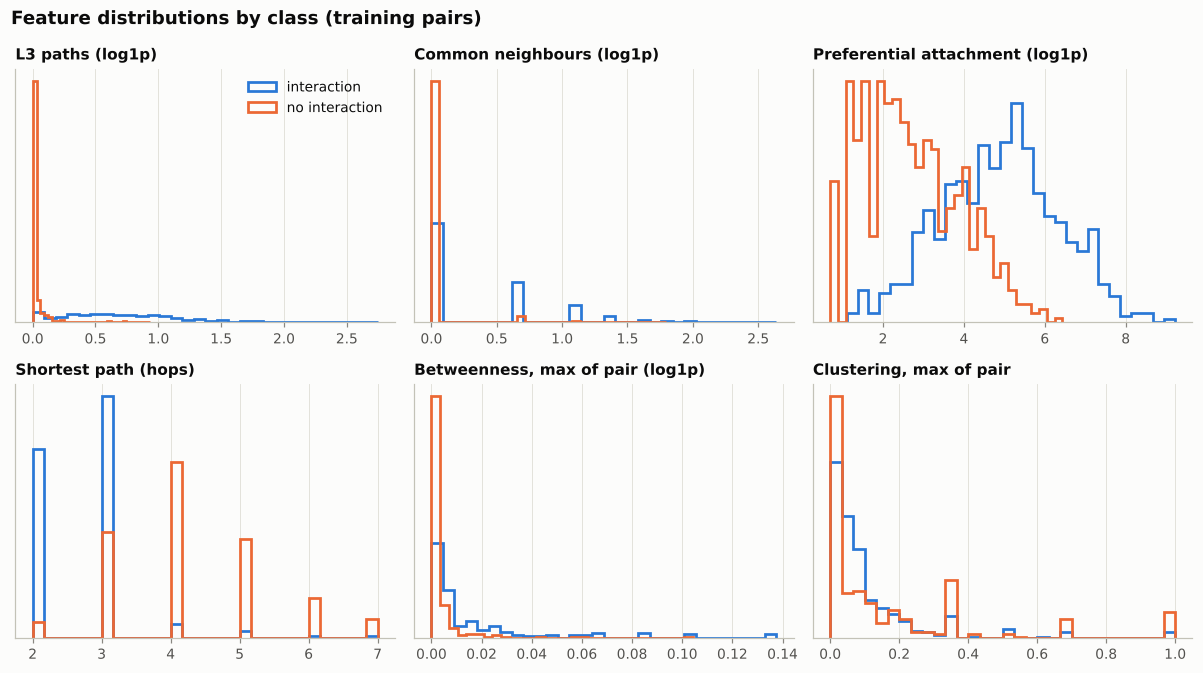

In [4]:
shown = {
    "l3": "L3 paths (log1p)",
    "common_neighbors": "Common neighbours (log1p)",
    "preferential_attachment": "Preferential attachment (log1p)",
    "shortest_path": "Shortest path (hops)",
    "betweenness_max": "Betweenness, max of pair (log1p)",
    "clustering_max": "Clustering, max of pair",
}
labels = np.where(y_train == 1, "interaction", "no interaction")

with plot_style():
    fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))
    for ax, (feature, title) in zip(axes.ravel(), shown.items()):
        values = X_train[feature]
        if feature not in ("shortest_path", "clustering_max"):
            values = np.log1p(values)
        for colour, cls in zip(PALETTE, ["interaction", "no interaction"]):
            ax.hist(values[labels == cls], bins=30, histtype="step", linewidth=1.8,
                    color=colour, density=True, label=cls)
        ax.set_title(title, fontsize=10)
        ax.set_yticks([])
        ax.grid(axis="y", visible=False)
    axes[0, 0].legend(loc="upper right")
    fig.suptitle("Feature distributions by class (training pairs)", x=0.01, ha="left",
                 fontweight="bold", color=INK["primary"])
    fig.tight_layout()
    plt.show()

**Paths of length three beat shared partners.** Triadic closure (common neighbours) is the textbook
link-prediction rule, yet half of the hidden interactions have *no* common neighbour at all, while almost all
of them are connected by at least one path of length three (table below). Kovács et al.
(2019) showed the same for real interactomes: two proteins interact when one resembles the other's
partners, so they are linked by many paths of length three (L3) rather than by shared partners. In the
duplication-divergence model this arises naturally, since a paralog inherits its ancestor's partners
without binding the ancestor itself.

In [5]:
pos, neg = X_test[y_test == 1], X_test[y_test == 0]
pd.DataFrame({
    "held-out interactions": [(pos.common_neighbors > 0).mean(), (pos.l3 > 0).mean()],
    "non-interacting pairs": [(neg.common_neighbors > 0).mean(), (neg.l3 > 0).mean()],
}, index=["share with ≥1 common neighbour", "connected by ≥1 path of length 3"])

,held-out interactions,non-interacting pairs
share with ≥1 common neighbour,0.50,0.039
connected by ≥1 path of length 3,0.96,0.303


## 3. Feature redundancy

Spearman correlations between features. Node-level metrics (degree, betweenness, closeness) are strongly
correlated with each other and with preferential attachment, as are the neighbourhood-overlap scores.
Tree models handle such redundancy well; it also means permutation importance (section 6) spreads credit
unevenly across correlated features.

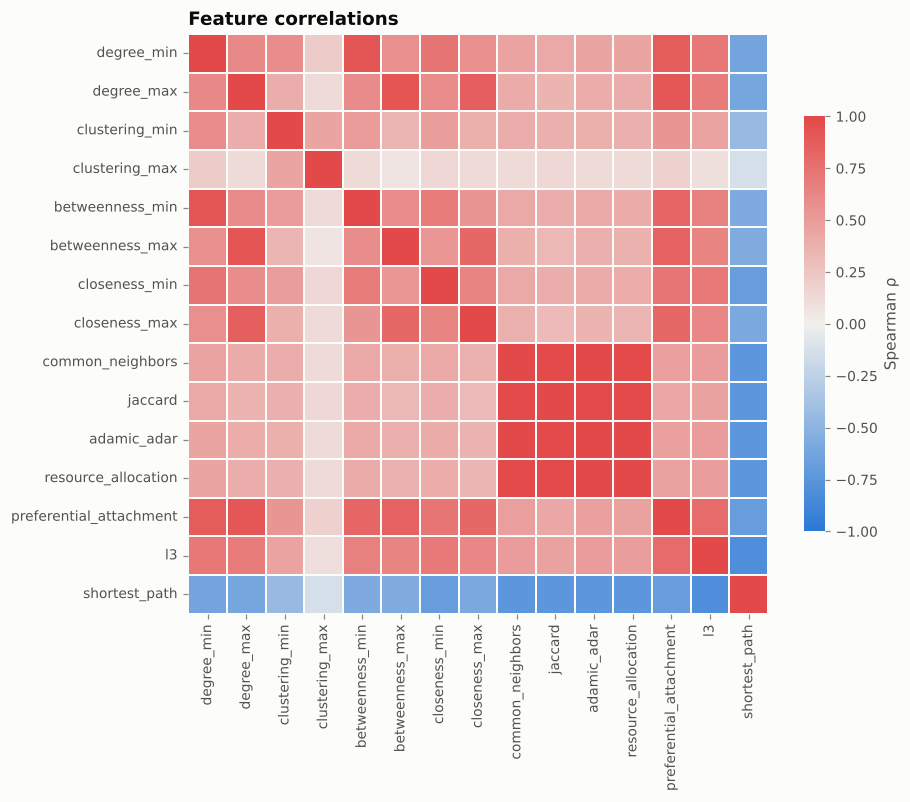

In [6]:
corr = X_train.corr(method="spearman")
diverging = LinearSegmentedColormap.from_list("blue_red", [PALETTE[0], "#f0efec", PALETTE[7]])

with plot_style():
    fig, ax = plt.subplots(figsize=(8.5, 7))
    sns.heatmap(corr, cmap=diverging, vmin=-1, vmax=1, center=0, square=True, linewidths=1,
                linecolor=INK["surface"], cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
    ax.grid(False)
    ax.set_title("Feature correlations")
    plt.show()

## 4. Train and evaluate

Three classifiers are cross-validated on the training pairs (5-fold stratified) and then scored on the
held-out test pairs, next to unsupervised heuristics that rank pairs by a single feature.

In [7]:
models = train_models(X_train, y_train, seed=SEED, cv_folds=5)
model_scores = {name: m.predict_proba(X_test) for name, m in models.items()}
baselines = heuristic_scores(X_test)
uniform_metrics = evaluate_scores(y_test, model_scores, baselines)
uniform_metrics[["kind", "roc_auc", "average_precision", "r_precision", "f1", "mcc"]]

,kind,roc_auc,average_precision,r_precision,f1,mcc
method,,,,,,
logistic_regression,model,0.975,0.978,0.935,0.935,0.871
random_forest,model,0.968,0.972,0.939,0.932,0.863
gradient_boosting,model,0.964,0.969,0.931,0.937,0.875
l3,heuristic,0.962,0.967,0.926,NaN,NaN
shortest_path,heuristic,0.892,0.839,0.789,NaN,NaN
preferential_attachment,heuristic,0.865,0.873,0.783,NaN,NaN
resource_allocation,heuristic,0.737,0.742,0.656,NaN,NaN
adamic_adar,heuristic,0.737,0.741,0.656,NaN,NaN
common_neighbors,heuristic,0.734,0.728,0.656,NaN,NaN


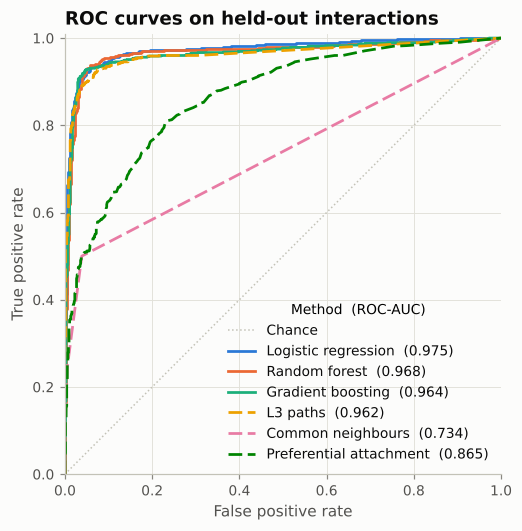

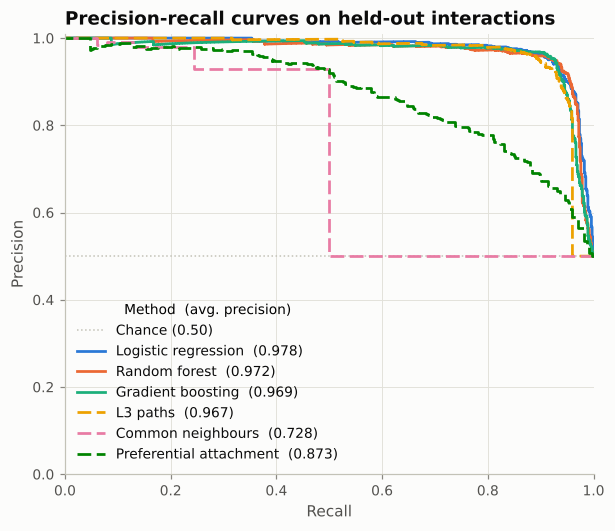

In [8]:
kinds = {**{n: "model" for n in model_scores}, **{n: "heuristic" for n in baselines}}
plotted = {**model_scores, **{n: baselines[n] for n in ["l3", "common_neighbors", "preferential_attachment"]}}
plot_roc_curves(y_test, plotted, kinds)
plt.show()
plot_pr_curves(y_test, plotted, kinds)
plt.show()

All three classifiers edge out the best single heuristic (L3). The gain is concentrated at high recall,
where L3 runs out of information (every pair without a length-3 path gets the same score of zero) and the
models fall back on degree, distance and centrality. The linear model performs on par with the tree
ensembles once the heavy-tailed features are log-transformed.

## 5. Harder negatives

Uniformly sampled negatives are mostly far apart in the network, which flatters every method: a pair four
hops apart is easy to reject. Sampling negatives two or three steps apart (`negative_strategy="local"`)
gives a more conservative, realistic estimate.

In [9]:
local_split = make_link_prediction_split(G, seed=SEED, negative_strategy="local")
X_train_l, X_test_l = build_feature_matrices(local_split, config)
local_models = train_models(X_train_l, local_split.train_labels, seed=SEED, cv_folds=0)
local_metrics = evaluate_scores(
    local_split.test_labels,
    {name: m.predict_proba(X_test_l) for name, m in local_models.items()},
    heuristic_scores(X_test_l),
)

comparison = pd.DataFrame({
    "uniform negatives": uniform_metrics["roc_auc"],
    "local negatives": local_metrics["roc_auc"],
}).sort_values("local negatives", ascending=False)
comparison

,uniform negatives,local negatives
method,,
gradient_boosting,0.964,0.901
random_forest,0.968,0.897
logistic_regression,0.975,0.897
l3,0.962,0.873
preferential_attachment,0.865,0.744
common_neighbors,0.734,0.456
adamic_adar,0.737,0.448
resource_allocation,0.737,0.436
shortest_path,0.892,0.421


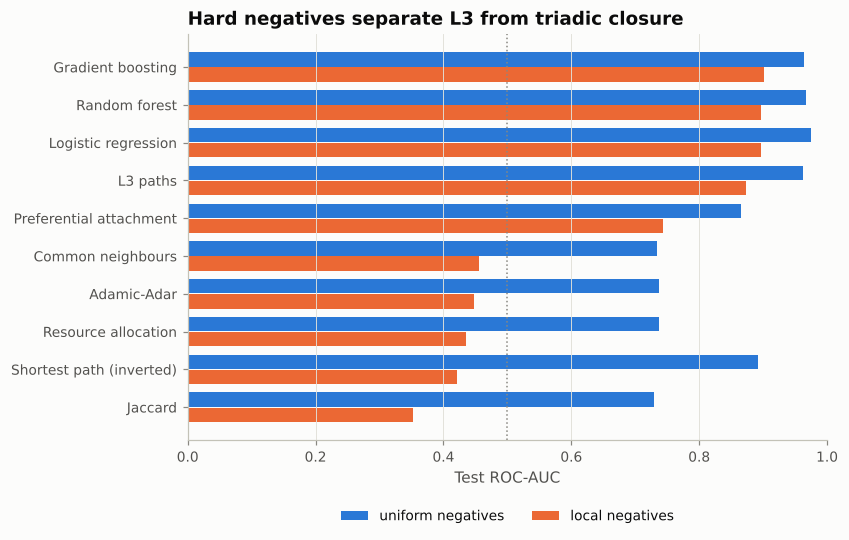

In [10]:
with plot_style():
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    y = np.arange(len(comparison))
    ax.barh(y - 0.2, comparison["uniform negatives"], height=0.38, color=PALETTE[0], label="uniform negatives")
    ax.barh(y + 0.2, comparison["local negatives"], height=0.38, color=PALETTE[1], label="local negatives")
    ax.axvline(0.5, color=INK["muted"], linewidth=1, linestyle=":")
    ax.set_yticks(y, [display_name(n) for n in comparison.index])
    ax.invert_yaxis()
    ax.set(xlim=(0, 1), xlabel="Test ROC-AUC")
    ax.grid(axis="y", visible=False)
    ax.set_title("Hard negatives separate L3 from triadic closure")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
    plt.show()

With local negatives, common-neighbour scores fall **below chance**: nearby non-interacting proteins
(for example paralogs) share more partners than true interactors do. L3 and the trained models remain well
above chance. Reporting both protocols, rather than only the flattering one, is good practice.

## 6. What the best model relies on

Permutation importance: the drop in test ROC-AUC when one feature is shuffled.

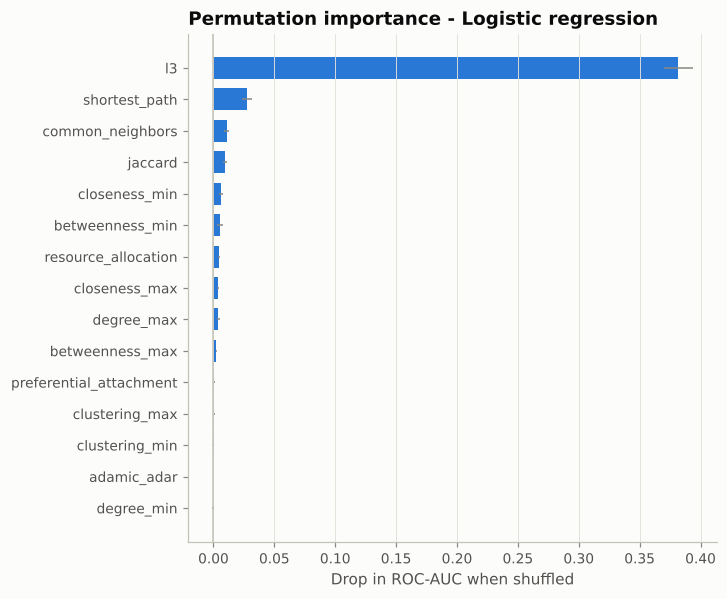

,feature,importance_mean,importance_std
0,l3,0.382,0.012
1,shortest_path,0.028,0.004
2,common_neighbors,0.011,0.002
3,jaccard,0.009,0.002
4,closeness_min,0.006,0.002
5,betweenness_min,0.005,0.002


In [11]:
best = uniform_metrics[uniform_metrics.kind == "model"].roc_auc.idxmax()
importance = compute_permutation_importance(models[best].estimator, X_test, y_test, n_repeats=10, seed=SEED)
plot_feature_importance(importance, title=f"Permutation importance - {display_name(best)}")
plt.show()
importance.head(6)

L3 dominates. Correlated features (degree, centralities, preferential attachment) share information, so
shuffling any single one of them costs little even though, together, they carry the signal used at high
recall.

## Conclusions

* Topology alone predicts held-out interactions with ROC-AUC ≈ 0.97 on this network.
* L3 paths are the single most informative feature, consistent with the complementarity principle of
  protein binding; triadic-closure scores are weak and break down entirely against hard negatives.
* Supervised models add value by combining L3 with degree, distance and centrality.
* Caveats: the network is synthetic; real interactomes are incomplete and biased towards well-studied
  proteins, so scores should be validated against held-out experimental data before biological use.